# Wine Dataset — Machine Learning Midterm Project

## 1. Dataset Loading and Overview

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.datasets import load_wine

os.makedirs("figures", exist_ok=True)

data = load_wine()

X = data.data
y = data.target

X_df = pd.DataFrame(
    X,
    columns=data.feature_names
)

print("Dataset: Wine")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Classes:", np.unique(y))

display(X_df.head())

Dataset: Wine
Samples: 178
Features: 13
Classes: [0 1 2]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [2]:
# Missing Values
print("MISSING VALUES")
print(X_df.isnull().sum())

# Duplicate Rows
print("\nDUPLICATE ROWS")
print(X_df.duplicated().sum())

# Data Types
print("\nDATA TYPES")
print(X_df.dtypes)

# Numerical and Categorical Features
numerical_features = X_df.select_dtypes(
    include=["number"]
).columns

categorical_features = X_df.select_dtypes(
    exclude=["number"]
).columns

print("\nNumerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

# Class Distribution
class_counts = pd.Series(y).value_counts().sort_index()

print("\nCLASS DISTRIBUTION")
print(class_counts)

MISSING VALUES
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

DUPLICATE ROWS
0

DATA TYPES
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline             

In [3]:
Q1 = X_df.quantile(0.25)
Q3 = X_df.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (X_df < lower_bound) |
    (X_df > upper_bound)
)

outlier_counts = outlier_mask.sum()

print("OUTLIER COUNTS PER FEATURE")
display(outlier_counts.to_frame(name="Outlier Count"))

print("Total outlier cells:", outlier_mask.sum().sum())
print("Rows with at least one outlier:", outlier_mask.any(axis=1).sum())

OUTLIER COUNTS PER FEATURE


,Outlier Count
alcohol,0
malic_acid,3
ash,3
alcalinity_of_ash,4
magnesium,4
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,2
color_intensity,4


Total outlier cells: 21
Rows with at least one outlier: 17


In [4]:
wine_statistics = X_df.describe().T

wine_statistics = wine_statistics.rename(columns={
    "mean": "Mean",
    "50%": "Median",
    "min": "Min",
    "max": "Max",
    "std": "Std",
    "25%": "Q1",
    "75%": "Q3"
})

wine_statistics = wine_statistics[
    ["Mean", "Median", "Min", "Max", "Std", "Q1", "Q3"]
]

print("WINE DATASET - DESCRIPTIVE STATISTICS")

display(wine_statistics.round(3))

print("Total features:", len(wine_statistics))

WINE DATASET - DESCRIPTIVE STATISTICS


,Mean,Median,Min,Max,Std,Q1,Q3
alcohol,13.001,13.050,11.03,14.83,0.812,12.362,13.678
malic_acid,2.336,1.865,0.74,5.80,1.117,1.602,3.082
ash,2.367,2.360,1.36,3.23,0.274,2.210,2.558
alcalinity_of_ash,19.495,19.500,10.60,30.00,3.340,17.200,21.500
magnesium,99.742,98.000,70.00,162.00,14.282,88.000,107.000
total_phenols,2.295,2.355,0.98,3.88,0.626,1.742,2.800
flavanoids,2.029,2.135,0.34,5.08,0.999,1.205,2.875
nonflavanoid_phenols,0.362,0.340,0.13,0.66,0.124,0.270,0.438
proanthocyanins,1.591,1.555,0.41,3.58,0.572,1.250,1.950
color_intensity,5.058,4.690,1.28,13.00,2.318,3.220,6.200


Total features: 13


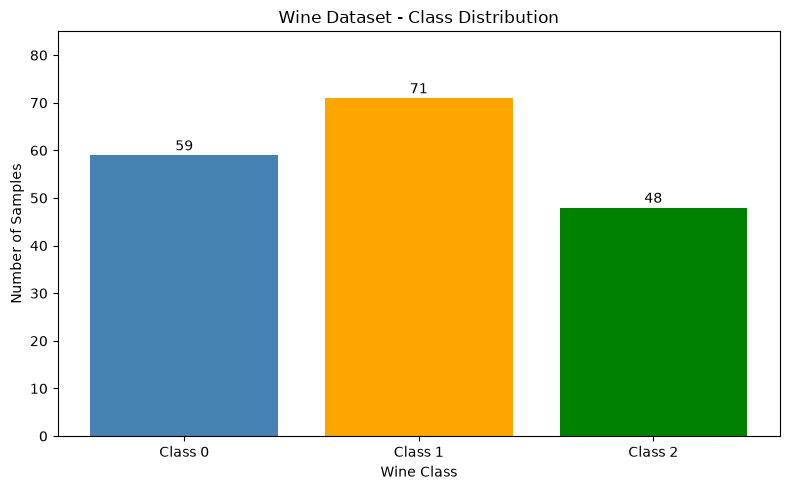

In [5]:
class_counts = pd.Series(y).value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Class 0", "Class 1", "Class 2"],
    class_counts.values,
    color=["steelblue", "orange", "green"]
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(int(bar.get_height())),
        ha="center"
    )

plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.title("Wine Dataset - Class Distribution")
plt.ylim(0, 85)
plt.tight_layout()

plt.savefig(
    "figures/wine_class_distribution.png",
    dpi=300
)

plt.show()

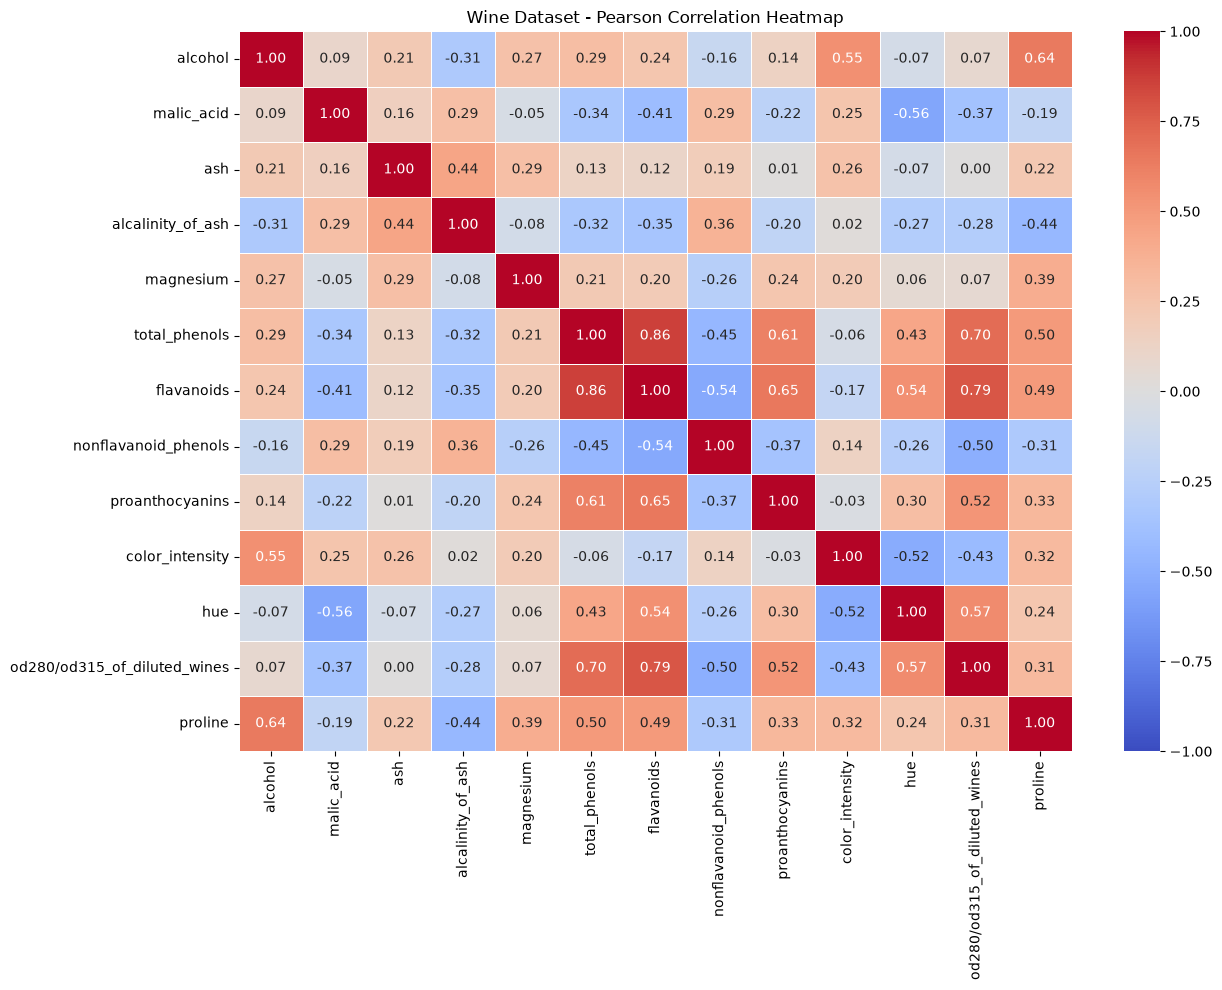

In [6]:
# Pearson Correlation Matrix
correlation_matrix = X_df.corr(method="pearson")

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Wine Dataset - Pearson Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "figures/wine_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Absolute Correlation
corr_abs = correlation_matrix.abs()

# Exclude diagonal and duplicate pairs
upper_triangle = corr_abs.where(
    np.triu(
        np.ones(corr_abs.shape),
        k=1
    ).astype(bool)
)

# Top 3 unique feature pairs
top_3_correlations = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
    .head(3)
)

print("TOP 3 STRONGEST FEATURE CORRELATIONS")
display(top_3_correlations)

TOP 3 STRONGEST FEATURE CORRELATIONS


total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
dtype: float64

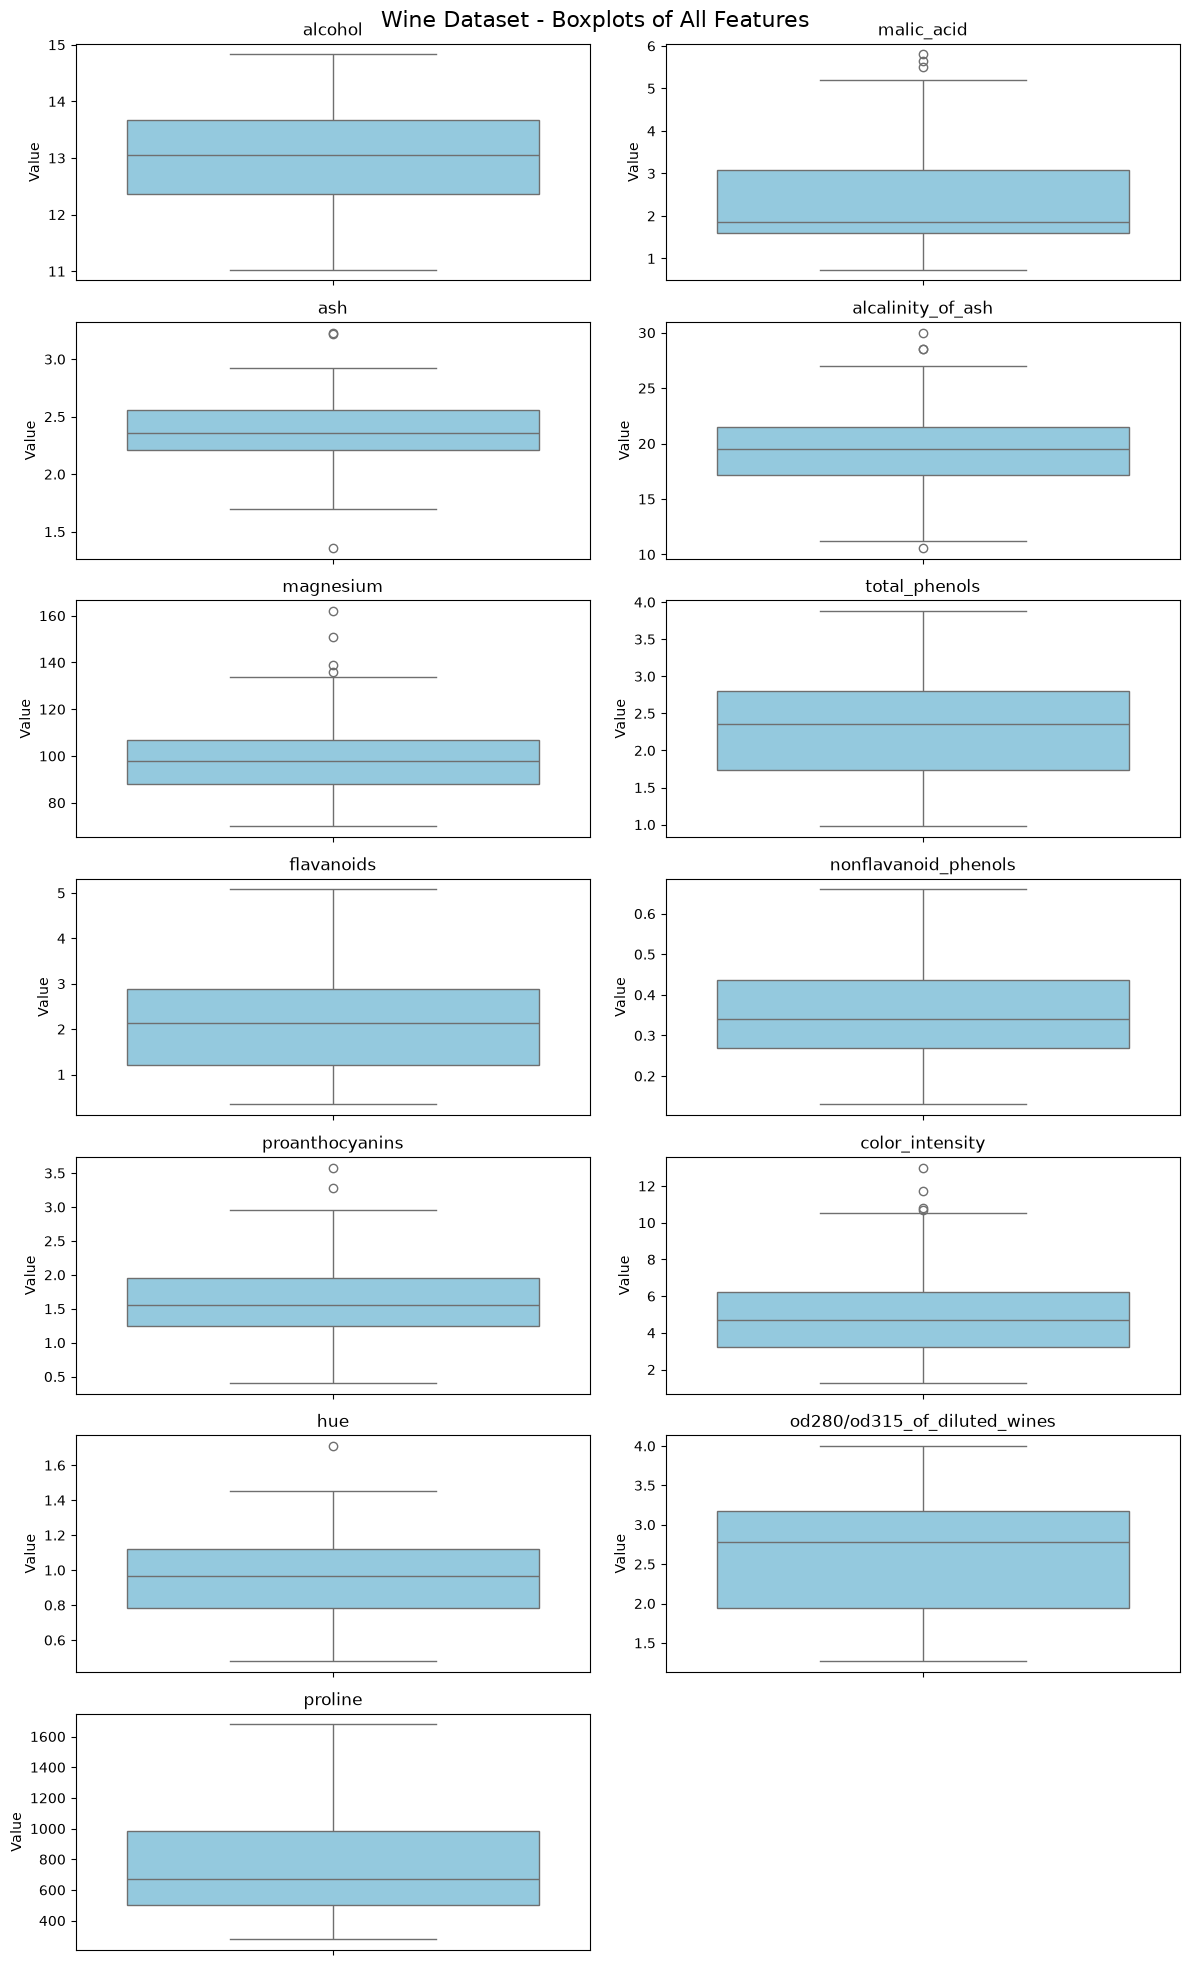

Total boxplots: 13


In [8]:
fig, axes = plt.subplots(7, 2, figsize=(12, 20))

axes = axes.flatten()

for i, column in enumerate(X_df.columns):
    sns.boxplot(
        y=X_df[column],
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(column)
    axes[i].set_ylabel("Value")

# Hide unused subplot
for j in range(len(X_df.columns), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Wine Dataset - Boxplots of All Features",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "figures/wine_all_features_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Total boxplots:", len(X_df.columns))

In [9]:
from sklearn.model_selection import train_test_split

SEEDS = [42, 52, 62]

# Preserve original row indices
original_indices = np.arange(len(y))

# Fixed 20% test split
remaining_idx, test_idx = train_test_split(
    original_indices,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_test = X[test_idx]
y_test = y[test_idx]

splits = {}

for seed in SEEDS:

    train_idx, val_idx = train_test_split(
        remaining_idx,
        test_size=0.125,
        stratify=y[remaining_idx],
        random_state=seed
    )

    splits[seed] = {
        "train_idx": train_idx,
        "val_idx": val_idx,
        "test_idx": test_idx,
        "X_train": X[train_idx],
        "X_val": X[val_idx],
        "y_train": y[train_idx],
        "y_val": y[val_idx]
    }

    # Check that subsets do not overlap
    assert len(set(train_idx) & set(val_idx)) == 0
    assert len(set(train_idx) & set(test_idx)) == 0
    assert len(set(val_idx) & set(test_idx)) == 0

    # Check total number of samples
    assert len(train_idx) + len(val_idx) + len(test_idx) == len(y)

    print(f"\nSeed {seed}")
    print("Training:", len(train_idx))
    print("Validation:", len(val_idx))
    print("Test:", len(test_idx))
    print("No overlap: PASSED")


Seed 42
Training: 124
Validation: 18
Test: 36
No overlap: PASSED

Seed 52
Training: 124
Validation: 18
Test: 36
No overlap: PASSED

Seed 62
Training: 124
Validation: 18
Test: 36
No overlap: PASSED


In [10]:
split_summary = []

for seed in SEEDS:
    split = splits[seed]

    for subset_name, indices in [
        ("Train", split["train_idx"]),
        ("Validation", split["val_idx"]),
        ("Test", split["test_idx"])
    ]:
        labels = y[indices]

        split_summary.append({
            "Seed": seed,
            "Subset": subset_name,
            "Samples": len(indices),
            "Percentage": round(
                len(indices) / len(y) * 100, 2
            ),
            "Class 0": int((labels == 0).sum()),
            "Class 1": int((labels == 1).sum()),
            "Class 2": int((labels == 2).sum())
        })

split_summary_df = pd.DataFrame(split_summary)

display(split_summary_df)

print("Total rows:", len(split_summary_df))

,Seed,Subset,Samples,Percentage,Class 0,Class 1,Class 2
0,42,Train,124,69.66,41,50,33
1,42,Validation,18,10.11,6,7,5
2,42,Test,36,20.22,12,14,10
3,52,Train,124,69.66,41,50,33
4,52,Validation,18,10.11,6,7,5
5,52,Test,36,20.22,12,14,10
6,62,Train,124,69.66,41,50,33
7,62,Validation,18,10.11,6,7,5
8,62,Test,36,20.22,12,14,10


Total rows: 9


In [11]:
for seed in SEEDS:
    assert np.array_equal(
        splits[seed]["test_idx"],
        test_idx
    )

    assert (
        len(splits[seed]["train_idx"]) +
        len(splits[seed]["val_idx"]) +
        len(splits[seed]["test_idx"])
    ) == len(y)

print("Fixed Test Set: PASSED")
print("Total Samples: PASSED")
print("All 3 seeds verified!")

Fixed Test Set: PASSED
Total Samples: PASSED
All 3 seeds verified!


In [ ]:
from sklearn.preprocessing import StandardScaler

scaled_splits = {}
scalers = {}

for seed in SEEDS:
    split = splits[seed]

    scaler = StandardScaler()
    
    X_train_scaled = scaler.fit_transform(
        split["X_train"]
    )

    X_val_scaled = scaler.transform(
        split["X_val"]
    )

    scalers[seed] = scaler

    scaled_splits[seed] = {
        "X_train": X_train_scaled,
        "X_val": X_val_scaled
    }

    print(f"Seed {seed}")
    print("Scaled Train:", X_train_scaled.shape)
    print("Scaled Validation:", X_val_scaled.shape)
    print("--------------------")

Seed 42
Scaled Train: (124, 13)
Scaled Validation: (18, 13)
--------------------
Seed 52
Scaled Train: (124, 13)
Scaled Validation: (18, 13)
--------------------
Seed 62
Scaled Train: (124, 13)
Scaled Validation: (18, 13)
--------------------


In [13]:
before_scaling = pd.DataFrame(
    splits[42]["X_train"],
    columns=data.feature_names
)

after_scaling = pd.DataFrame(
    scaled_splits[42]["X_train"],
    columns=data.feature_names
)

print("BEFORE SCALING:")
display(before_scaling.head(5).round(3))

print("AFTER SCALING:")
display(after_scaling.head(5).round(3))

print("Original shape:", before_scaling.shape)
print("Scaled shape:", after_scaling.shape)

BEFORE SCALING:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
1,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
2,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
3,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
4,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


AFTER SCALING:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,-0.018,1.089,-0.040,-0.308,0.433,-1.343,-1.322,0.353,-1.118,0.126,-1.227,-1.224,-0.209
1,0.440,0.892,0.073,0.609,-0.506,-0.491,-1.260,0.770,-0.572,1.512,-1.811,-1.415,-0.291
2,-1.465,-0.772,-1.397,0.395,-0.908,-0.412,-0.387,-0.482,-0.079,-1.344,-0.013,1.098,-0.800
3,-0.703,2.010,1.392,2.139,0.165,-0.065,0.165,0.603,0.238,-1.287,-0.147,0.789,-1.226
4,-2.469,-0.734,-0.605,0.609,-0.975,0.345,0.206,1.354,0.766,-1.367,3.405,0.422,-1.089


Original shape: (124, 13)
Scaled shape: (124, 13)


In [14]:
representations = {}

for seed in SEEDS:
    representations[seed] = {
        "Unscaled": {
            "X_train": splits[seed]["X_train"],
            "X_val": splits[seed]["X_val"]
        },
        "Scaled": {
            "X_train": scaled_splits[seed]["X_train"],
            "X_val": scaled_splits[seed]["X_val"]
        }
    }

    for rep_name, rep_data in representations[seed].items():
        print(
            f"Seed {seed} | {rep_name} | "
            f"Train: {rep_data['X_train'].shape} | "
            f"Validation: {rep_data['X_val'].shape}"
        )

Seed 42 | Unscaled | Train: (124, 13) | Validation: (18, 13)
Seed 42 | Scaled | Train: (124, 13) | Validation: (18, 13)
Seed 52 | Unscaled | Train: (124, 13) | Validation: (18, 13)
Seed 52 | Scaled | Train: (124, 13) | Validation: (18, 13)
Seed 62 | Unscaled | Train: (124, 13) | Validation: (18, 13)
Seed 62 | Scaled | Train: (124, 13) | Validation: (18, 13)


In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

model_configs = []

# Decision Tree configurations
for depth in [2, 3, 5, 10, None]:
    model_configs.append({
        "algorithm": "Decision Tree",
        "parameter": depth
    })

# KNN configurations
for k in [1, 3, 5, 7, 11]:
    model_configs.append({
        "algorithm": "KNN",
        "parameter": k
    })

# Gaussian Naive Bayes
model_configs.append({
    "algorithm": "GaussianNB",
    "parameter": "Default"
})

configs_df = pd.DataFrame(model_configs)

display(configs_df)

print("Configurations:", len(model_configs))
print("Total fits:", len(model_configs) * 2 * len(SEEDS))

,algorithm,parameter
0,Decision Tree,2
1,Decision Tree,3
2,Decision Tree,5
3,Decision Tree,10
4,Decision Tree,None
5,KNN,1
6,KNN,3
7,KNN,5
8,KNN,7
9,KNN,11


Configurations: 11
Total fits: 66


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model, X_train, y_train, X_val, y_val):

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # Probability scores for all three classes
    val_prob = model.predict_proba(X_val)

    # Multiclass ROC-AUC (One-vs-Rest)
    val_auc = roc_auc_score(
        y_val,
        val_prob,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    )

    return {
        "train_accuracy": accuracy_score(
            y_train, train_pred
        ),

        "train_macro_f1": f1_score(
            y_train, train_pred,
            average="macro",
            zero_division=0
        ),

        "val_accuracy": accuracy_score(
            y_val, val_pred
        ),

        "val_macro_precision": precision_score(
            y_val, val_pred,
            average="macro",
            zero_division=0
        ),

        "val_macro_recall": recall_score(
            y_val, val_pred,
            average="macro",
            zero_division=0
        ),

        "val_macro_f1": f1_score(
            y_val, val_pred,
            average="macro",
            zero_division=0
        ),

        "val_roc_auc": val_auc
    }

print("Wine multiclass evaluation function is ready!")

Wine multiclass evaluation function is ready!


In [18]:
classifier_results = []
trained_models = {}

for seed in SEEDS:
    for rep_name, rep_data in representations[seed].items():

        X_train = rep_data["X_train"]
        X_val = rep_data["X_val"]

        y_train = splits[seed]["y_train"]
        y_val = splits[seed]["y_val"]

        for config in model_configs:

            algorithm = config["algorithm"]
            parameter = config["parameter"]

            if algorithm == "Decision Tree":
                model = DecisionTreeClassifier(
                    max_depth=parameter,
                    random_state=seed
                )
                config_id = f"DT_depth_{parameter}_{rep_name}"

            elif algorithm == "KNN":
                model = KNeighborsClassifier(
                    n_neighbors=parameter,
                    weights="uniform",
                    metric="euclidean"
                )
                config_id = f"KNN_k_{parameter}_{rep_name}"

            else:
                model = GaussianNB()
                config_id = f"GNB_default_{rep_name}"

            # Train model
            model.fit(X_train, y_train)

            # Evaluate on training and validation
            metrics = evaluate_model(
                model,
                X_train,
                y_train,
                X_val,
                y_val
            )

            run_id = f"{config_id}_seed_{seed}"

            classifier_results.append({
                "dataset": "Wine",
                "run_id": run_id,
                "config_id": config_id,
                "algorithm": algorithm,
                "representation": rep_name,
                "parameter": str(parameter),
                "seed": seed,
                **metrics
            })

            trained_models[run_id] = model

classifier_runs_df = pd.DataFrame(classifier_results)

print("Total trained models:", len(classifier_runs_df))

display(classifier_runs_df.head(10))

print("\nModels per seed:")
print(classifier_runs_df.groupby("seed").size())

print("\nModels per representation:")
print(classifier_runs_df.groupby("representation").size())

print("\nModels per algorithm:")
print(classifier_runs_df.groupby("algorithm").size())

assert len(classifier_runs_df) == 66

print("\nAll 66 Wine classification runs completed!")

Total trained models: 66


,dataset,run_id,config_id,algorithm,representation,parameter,seed,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,Wine,DT_depth_2_Unscaled_seed_42,DT_depth_2_Unscaled,Decision Tree,Unscaled,2,42,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596
1,Wine,DT_depth_3_Unscaled_seed_42,DT_depth_3_Unscaled,Decision Tree,Unscaled,3,42,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645
2,Wine,DT_depth_5_Unscaled_seed_42,DT_depth_5_Unscaled,Decision Tree,Unscaled,5,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
3,Wine,DT_depth_10_Unscaled_seed_42,DT_depth_10_Unscaled,Decision Tree,Unscaled,10,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
4,Wine,DT_depth_None_Unscaled_seed_42,DT_depth_None_Unscaled,Decision Tree,Unscaled,None,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
5,Wine,KNN_k_1_Unscaled_seed_42,KNN_k_1_Unscaled,KNN,Unscaled,1,42,1.000000,1.000000,0.666667,0.675000,0.660317,0.664646,0.745174
6,Wine,KNN_k_3_Unscaled_seed_42,KNN_k_3_Unscaled,KNN,Unscaled,3,42,0.846774,0.841468,0.611111,0.611111,0.601587,0.604118,0.800343
7,Wine,KNN_k_5_Unscaled_seed_42,KNN_k_5_Unscaled,KNN,Unscaled,5,42,0.798387,0.783717,0.722222,0.715873,0.715873,0.712821,0.875905
8,Wine,KNN_k_7_Unscaled_seed_42,KNN_k_7_Unscaled,KNN,Unscaled,7,42,0.814516,0.807069,0.666667,0.671429,0.668254,0.660451,0.840490
9,Wine,KNN_k_11_Unscaled_seed_42,KNN_k_11_Unscaled,KNN,Unscaled,11,42,0.750000,0.740457,0.611111,0.615873,0.601587,0.599845,0.819811



Models per seed:
seed
42    22
52    22
62    22
dtype: int64

Models per representation:
representation
Scaled      33
Unscaled    33
dtype: int64

Models per algorithm:
algorithm
Decision Tree    30
GaussianNB        6
KNN              30
dtype: int64

All 66 Wine classification runs completed!


In [20]:
metric_columns = [
    "train_accuracy",
    "train_macro_f1",
    "val_accuracy",
    "val_macro_precision",
    "val_macro_recall",
    "val_macro_f1",
    "val_roc_auc"
]

group_columns = [
    "dataset",
    "config_id",
    "algorithm",
    "representation",
    "parameter"
]

classifier_summary_df = (
    classifier_runs_df
    .groupby(group_columns)[metric_columns]
    .agg(["mean", "std"])
    .reset_index()
)

# Flatten column names
classifier_summary_df.columns = [
    "_".join(col).strip("_")
    if isinstance(col, tuple) else col
    for col in classifier_summary_df.columns
]

# Sort by assignment selection rules
classifier_summary_df = (
    classifier_summary_df
    .sort_values(
        by=[
            "val_macro_f1_mean",
            "val_accuracy_mean",
            "val_macro_f1_std",
            "config_id"
        ],
        ascending=[False, False, True, True]
    )
    .reset_index(drop=True)
)

print("Total configurations:", len(classifier_summary_df))

display(classifier_summary_df.round(4))

best_config = classifier_summary_df.iloc[0]

print("BEST WINE CONFIGURATION")
print("------------------------")
print("Config ID:", best_config["config_id"])
print("Algorithm:", best_config["algorithm"])
print("Representation:", best_config["representation"])
print("Parameter:", best_config["parameter"])

print(
    "Mean Validation Macro-F1:",
    round(best_config["val_macro_f1_mean"], 4)
)

print(
    "Mean Validation Accuracy:",
    round(best_config["val_accuracy_mean"], 4)
)

print(
    "Macro-F1 Standard Deviation:",
    round(best_config["val_macro_f1_std"], 4)
)

assert len(classifier_summary_df) == 22
assert classifier_runs_df.groupby("config_id")["seed"].nunique().eq(3).all()

Total configurations: 22


,dataset,config_id,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std
0,Wine,KNN_k_11_Scaled,KNN,Scaled,11,0.9651,0.0047,0.9656,0.0048,0.9815,0.0321,0.9815,0.0321,0.9841,0.0275,0.9814,0.0323,1.0000,0.0000
1,Wine,KNN_k_5_Scaled,KNN,Scaled,5,0.9758,0.0000,0.9762,0.0005,0.9815,0.0321,0.9815,0.0321,0.9841,0.0275,0.9814,0.0323,1.0000,0.0000
2,Wine,KNN_k_7_Scaled,KNN,Scaled,7,0.9597,0.0081,0.9603,0.0080,0.9815,0.0321,0.9815,0.0321,0.9841,0.0275,0.9814,0.0323,1.0000,0.0000
3,Wine,KNN_k_1_Scaled,KNN,Scaled,1,1.0000,0.0000,1.0000,0.0000,0.9630,0.0321,0.9683,0.0275,0.9683,0.0275,0.9658,0.0296,0.9749,0.0218
4,Wine,GNB_default_Scaled,GaussianNB,Scaled,Default,0.9839,0.0000,0.9840,0.0005,0.9630,0.0321,0.9676,0.0289,0.9656,0.0300,0.9638,0.0314,1.0000,0.0000
5,Wine,GNB_default_Unscaled,GaussianNB,Unscaled,Default,0.9839,0.0000,0.9840,0.0005,0.9630,0.0321,0.9676,0.0289,0.9656,0.0300,0.9638,0.0314,1.0000,0.0000
6,Wine,DT_depth_10_Scaled,Decision Tree,Scaled,10,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
7,Wine,DT_depth_10_Unscaled,Decision Tree,Unscaled,10,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
8,Wine,DT_depth_3_Scaled,Decision Tree,Scaled,3,0.9919,0.0000,0.9926,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431
9,Wine,DT_depth_3_Unscaled,Decision Tree,Unscaled,3,0.9919,0.0000,0.9926,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431


BEST WINE CONFIGURATION
------------------------
Config ID: KNN_k_11_Scaled
Algorithm: KNN
Representation: Scaled
Parameter: 11
Mean Validation Macro-F1: 0.9814
Mean Validation Accuracy: 0.9815
Macro-F1 Standard Deviation: 0.0323


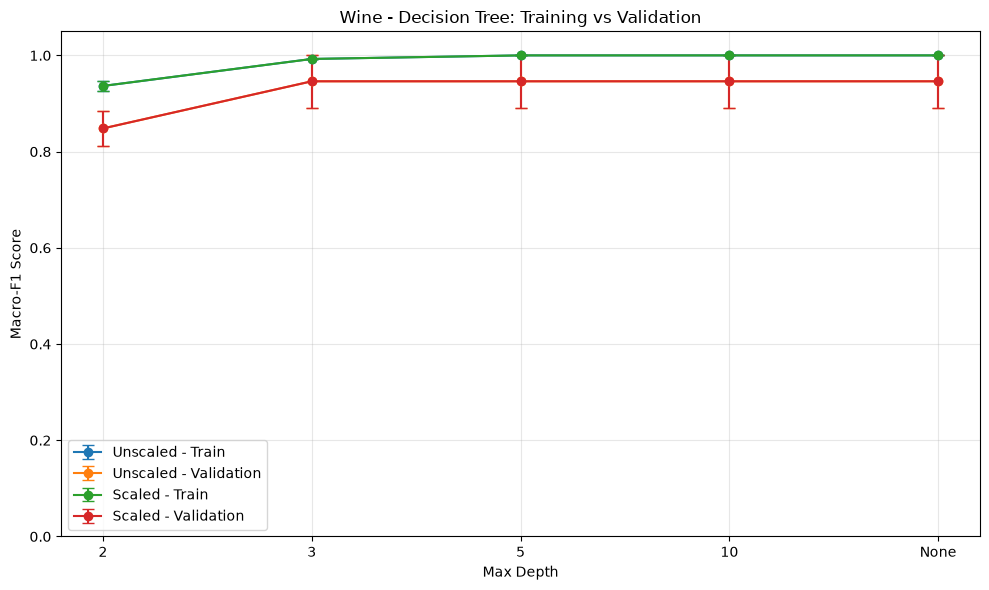

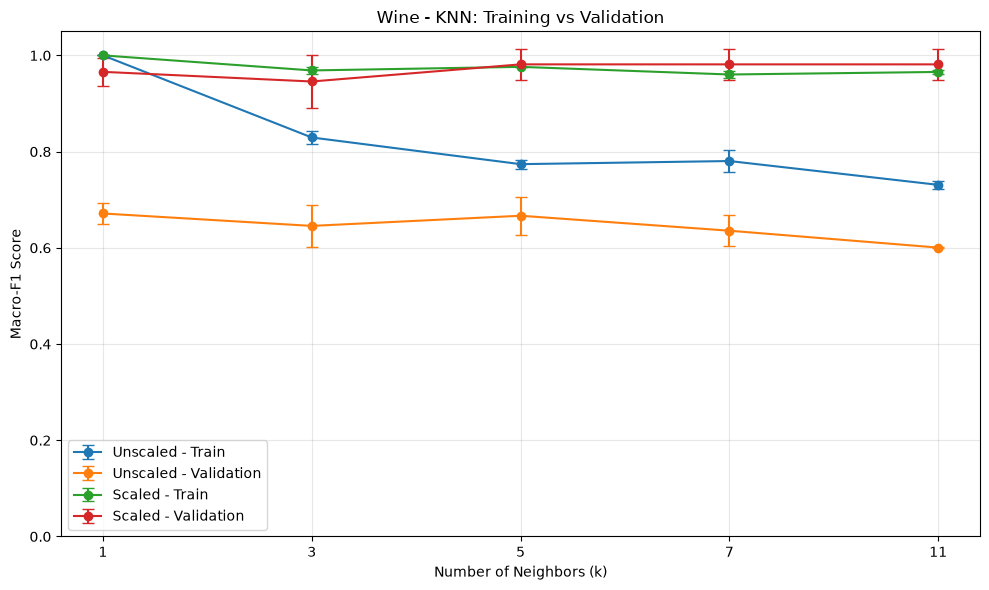

Both Wine classification comparison plots saved!


In [21]:
import matplotlib.pyplot as plt
import numpy as np

plot_settings = [
    ("Decision Tree", [2, 3, 5, 10, None], "Max Depth",
     "wine_decision_tree_comparison.png"),
    ("KNN", [1, 3, 5, 7, 11], "Number of Neighbors (k)",
     "wine_knn_comparison.png")
]

for algorithm, params, xlabel, filename in plot_settings:

    plt.figure(figsize=(10, 6))
    subset = classifier_summary_df[
        classifier_summary_df["algorithm"] == algorithm
    ]

    for rep in ["Unscaled", "Scaled"]:
        rep_df = subset[subset["representation"] == rep]

        for metric, label_style in [
            ("train_macro_f1", "Train"),
            ("val_macro_f1", "Validation")
        ]:
            means = []
            stds = []

            for param in params:
                row = rep_df[
                    rep_df["parameter"] == str(param)
                ].iloc[0]

                means.append(row[f"{metric}_mean"])
                stds.append(row[f"{metric}_std"])

            plt.errorbar(
                range(len(params)),
                means,
                yerr=stds,
                marker="o",
                capsize=4,
                label=f"{rep} - {label_style}"
            )

    plt.xticks(range(len(params)), [str(p) for p in params])
    plt.xlabel(xlabel)
    plt.ylabel("Macro-F1 Score")
    plt.title(f"Wine - {algorithm}: Training vs Validation")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(f"figures/{filename}", dpi=300)
    plt.show()

print("Both Wine classification comparison plots saved!")

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Selected model from Seed 42
best_config_id = best_config["config_id"]
best_run_id = f"{best_config_id}_seed_42"

final_model = trained_models[best_run_id]

# Use ONLY Seed 42 scaler
X_test_scaled = scalers[42].transform(X_test)

# Select the correct representation
if best_config["representation"] == "Scaled":
    X_test_final = X_test_scaled
else:
    X_test_final = X_test

# Test predictions
y_test_pred = final_model.predict(X_test_final)
y_test_prob = final_model.predict_proba(X_test_final)

# Final test metrics
classifier_test_df = pd.DataFrame([{
    "dataset": "Wine",
    "config_id": best_config_id,
    "seed": 42,
    "test_accuracy": accuracy_score(y_test, y_test_pred),
    "test_macro_precision": precision_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "test_macro_recall": recall_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "test_macro_f1": f1_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "test_roc_auc": roc_auc_score(
        y_test,
        y_test_prob,
        labels=final_model.classes_,
        multi_class="ovr",
        average="macro"
    )
}])

print("FINAL WINE TEST RESULTS")
display(classifier_test_df.round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

FINAL WINE TEST RESULTS


,dataset,config_id,seed,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,Wine,KNN_k_11_Scaled,42,1.0,1.0,1.0,1.0,1.0



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



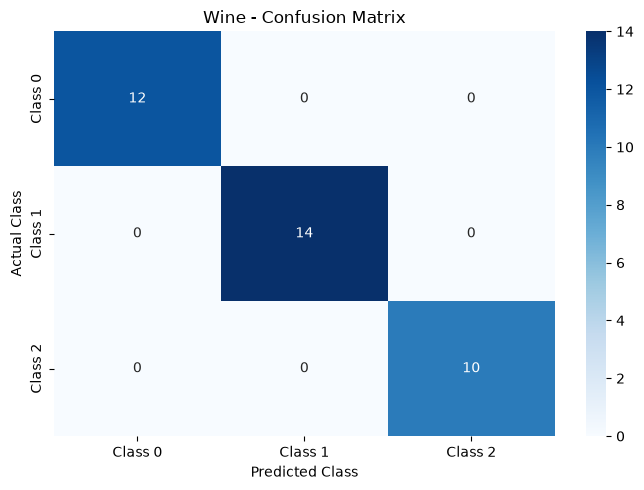

Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

MANUAL METRICS FOR CLASS 0
TP: 12
FP: 0
FN: 0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [23]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1", "Class 2"],
    yticklabels=["Class 0", "Class 1", "Class 2"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Wine - Confusion Matrix")

plt.tight_layout()
plt.savefig("figures/wine_confusion_matrix.png", dpi=300)
plt.show()

print("Confusion Matrix:")
print(cm)

# Manual Precision, Recall, F1 for Class 0
TP = cm[0, 0]
FP = cm[1, 0] + cm[2, 0]
FN = cm[0, 1] + cm[0, 2]

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

print("\nMANUAL METRICS FOR CLASS 0")
print("TP:", TP)
print("FP:", FP)
print("FN:", FN)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

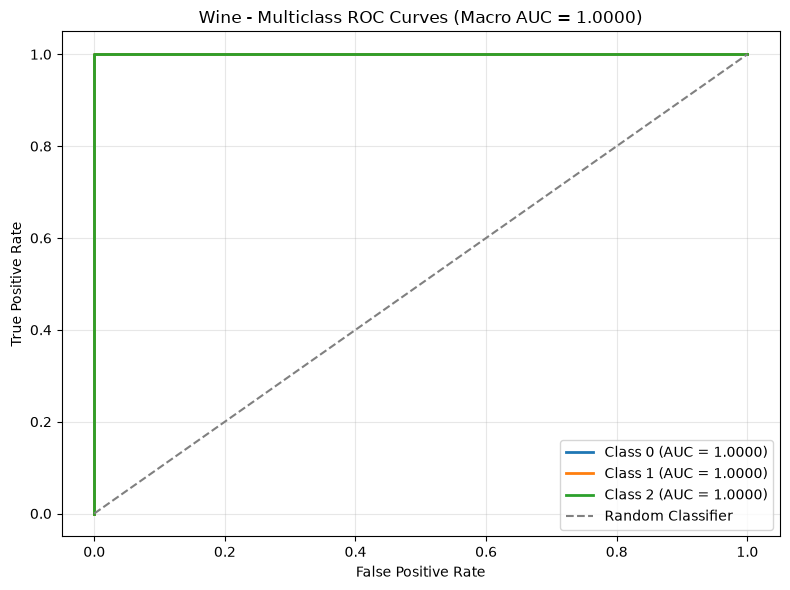

Class 0 AUC: 1.0000
Class 1 AUC: 1.0000
Class 2 AUC: 1.0000
Macro ROC-AUC: 1.0000


In [24]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Convert true labels to One-vs-Rest format
classes = final_model.classes_
y_test_binary = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8, 6))

class_auc_values = []

for i, class_label in enumerate(classes):

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_test_prob[:, i]
    )

    class_auc = auc(fpr, tpr)
    class_auc_values.append(class_auc)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"Class {class_label} (AUC = {class_auc:.4f})"
    )

macro_auc = roc_auc_score(
    y_test,
    y_test_prob,
    labels=classes,
    multi_class="ovr",
    average="macro"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"Wine - Multiclass ROC Curves (Macro AUC = {macro_auc:.4f})")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/wine_roc_curves.png", dpi=300)
plt.show()

for class_label, score in zip(classes, class_auc_values):
    print(f"Class {class_label} AUC: {score:.4f}")

print(f"Macro ROC-AUC: {macro_auc:.4f}")

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd
import numpy as np

kmeans_results = []
kmeans_models = {}

for seed in SEEDS:
    for rep_name, rep_data in representations[seed].items():

        X_train = rep_data["X_train"]
        X_val = rep_data["X_val"]
        y_val = splits[seed]["y_val"]

        # Train K-Means without class labels
        model = KMeans(
            n_clusters=3,
            random_state=seed,
            n_init=10
        )

        model.fit(X_train)

        # Predict validation clusters
        val_clusters = model.predict(X_val)

        # Validation ARI
        val_ari = adjusted_rand_score(
            y_val,
            val_clusters
        )

        # Validation Silhouette
        unique_clusters = np.unique(val_clusters)

        if 2 <= len(unique_clusters) < len(X_val):
            val_silhouette = silhouette_score(
                X_val,
                val_clusters
            )
        else:
            val_silhouette = np.nan

        run_id = f"KMeans_{rep_name}_seed_{seed}"

        kmeans_results.append({
            "dataset": "Wine",
            "run_id": run_id,
            "representation": rep_name,
            "seed": seed,
            "n_clusters": 3,
            "train_inertia": model.inertia_,
            "val_ari": val_ari,
            "val_silhouette": val_silhouette
        })

        kmeans_models[run_id] = model

kmeans_runs_df = pd.DataFrame(kmeans_results)

print("Total K-Means Fits:", len(kmeans_runs_df))

display(kmeans_runs_df.round(4))

c:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with M

Total K-Means Fits: 6


c:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,dataset,run_id,representation,seed,n_clusters,train_inertia,val_ari,val_silhouette
0,Wine,KMeans_Unscaled_seed_42,Unscaled,42,3,1.350496e+06,0.2828,0.4870
1,Wine,KMeans_Scaled_seed_42,Scaled,42,3,8.747391e+02,1.0000,0.2516
2,Wine,KMeans_Unscaled_seed_52,Unscaled,52,3,1.303675e+06,0.4006,0.5559
3,Wine,KMeans_Scaled_seed_52,Scaled,52,3,8.904355e+02,1.0000,0.3010
4,Wine,KMeans_Unscaled_seed_62,Unscaled,62,3,1.390754e+06,0.4006,0.6867
5,Wine,KMeans_Scaled_seed_62,Scaled,62,3,8.722466e+02,1.0000,0.2726


In [26]:
kmeans_summary_df = (
    kmeans_runs_df
    .groupby(["dataset", "representation"])[
        ["train_inertia", "val_ari", "val_silhouette"]
    ]
    .agg(["mean", "std"])
    .reset_index()
)

# Flatten column names
kmeans_summary_df.columns = [
    "_".join(col).strip("_")
    if isinstance(col, tuple) else col
    for col in kmeans_summary_df.columns
]

print("Total K-Means Summary Rows:", len(kmeans_summary_df))

display(kmeans_summary_df.round(4))

Total K-Means Summary Rows: 2


,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std
0,Wine,Scaled,8.791404e+02,9.8609,1.0000,0.000,0.2751,0.0248
1,Wine,Unscaled,1.348308e+06,43580.9098,0.3613,0.068,0.5765,0.1014


In [27]:
from sklearn.metrics import adjusted_rand_score, silhouette_score
import numpy as np
import pandas as pd

kmeans_test_results = []
test_cluster_predictions = {}

for rep_name in ["Unscaled", "Scaled"]:

    run_id = f"KMeans_{rep_name}_seed_42"
    model = kmeans_models[run_id]

    # Use the same representation as training
    if rep_name == "Scaled":
        X_test_rep = scalers[42].transform(X_test)
    else:
        X_test_rep = X_test

    # Predict clusters on fixed test set
    test_clusters = model.predict(X_test_rep)

    test_cluster_predictions[rep_name] = test_clusters

    # ARI compares clusters with true classes
    test_ari = adjusted_rand_score(
        y_test,
        test_clusters
    )

    # Silhouette uses only features and clusters
    unique_clusters = np.unique(test_clusters)

    if 2 <= len(unique_clusters) < len(X_test_rep):
        test_silhouette = silhouette_score(
            X_test_rep,
            test_clusters
        )
    else:
        test_silhouette = np.nan

    cluster_counts = np.bincount(
        test_clusters,
        minlength=3
    )

    kmeans_test_results.append({
        "dataset": "Wine",
        "representation": rep_name,
        "seed": 42,
        "n_clusters": 3,
        "test_ari": test_ari,
        "test_silhouette": test_silhouette,
        "cluster_0_count": cluster_counts[0],
        "cluster_1_count": cluster_counts[1],
        "cluster_2_count": cluster_counts[2]
    })

kmeans_test_df = pd.DataFrame(kmeans_test_results)

print("WINE K-MEANS TEST RESULTS")
display(kmeans_test_df.round(4))

print("Total Test Evaluations:", len(kmeans_test_df))

WINE K-MEANS TEST RESULTS


,dataset,representation,seed,n_clusters,test_ari,test_silhouette,cluster_0_count,cluster_1_count,cluster_2_count
0,Wine,Unscaled,42,3,0.3733,0.4929,14,10,12
1,Wine,Scaled,42,3,0.9088,0.2711,13,13,10


Total Test Evaluations: 2


In [28]:
import pandas as pd

contingency_tables = {}

for rep_name in ["Unscaled", "Scaled"]:

    test_clusters = test_cluster_predictions[rep_name]

    contingency_table = pd.crosstab(
        pd.Series(y_test, name="True Class"),
        pd.Series(test_clusters, name="Predicted Cluster")
    )

    contingency_table = contingency_table.reindex(
        index=[0, 1, 2],
        columns=[0, 1, 2],
        fill_value=0
    )

    contingency_tables[rep_name] = contingency_table

    print(f"\nWINE - {rep_name.upper()} K-MEANS")
    display(contingency_table)

    print("Total Samples:", contingency_table.to_numpy().sum())


WINE - UNSCALED K-MEANS


Predicted Cluster,0,1,2
True Class,,,
0,2,10,0
1,5,0,9
2,7,0,3


Total Samples: 36

WINE - SCALED K-MEANS


Predicted Cluster,0,1,2
True Class,,,
0,12,0,0
1,1,13,0
2,0,0,10


Total Samples: 36


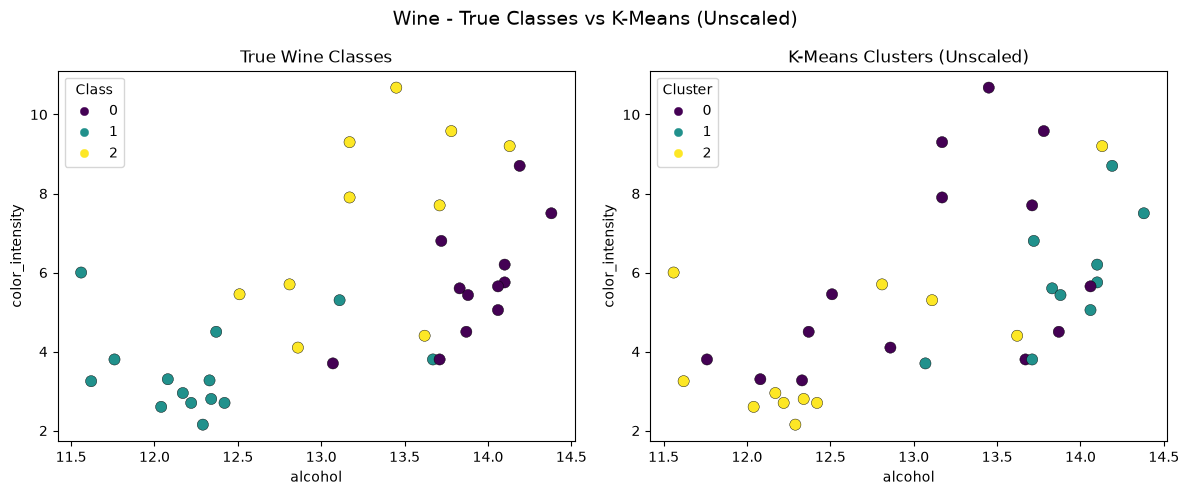

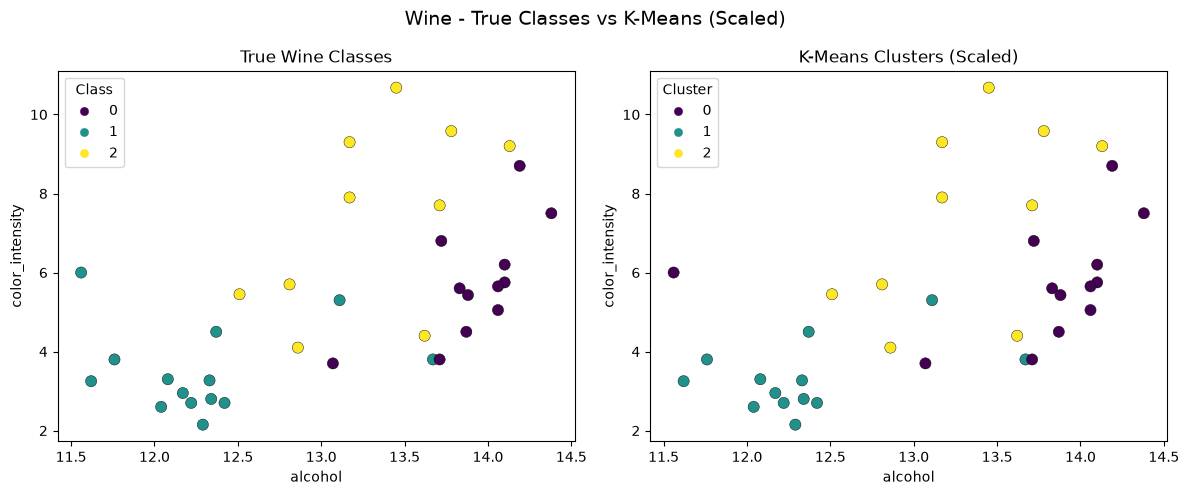

Both Wine K-Means visualizations saved!


In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Select two original features
feature_x = "alcohol"
feature_y = "color_intensity"

x_index = list(data.feature_names).index(feature_x)
y_index = list(data.feature_names).index(feature_y)

for rep_name in ["Unscaled", "Scaled"]:

    clusters = test_cluster_predictions[rep_name]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Left: True Classes
    scatter1 = axes[0].scatter(
        X_test[:, x_index],
        X_test[:, y_index],
        c=y_test,
        cmap="viridis",
        s=65,
        edgecolors="black",
        linewidths=0.3
    )

    axes[0].set_title("True Wine Classes")
    axes[0].set_xlabel(feature_x)
    axes[0].set_ylabel(feature_y)

    axes[0].legend(
        *scatter1.legend_elements(),
        title="Class"
    )

    # Right: Predicted Clusters
    scatter2 = axes[1].scatter(
        X_test[:, x_index],
        X_test[:, y_index],
        c=clusters,
        cmap="viridis",
        s=65,
        edgecolors="black",
        linewidths=0.3
    )

    axes[1].set_title(f"K-Means Clusters ({rep_name})")
    axes[1].set_xlabel(feature_x)
    axes[1].set_ylabel(feature_y)

    axes[1].legend(
        *scatter2.legend_elements(),
        title="Cluster"
    )

    fig.suptitle(
        f"Wine - True Classes vs K-Means ({rep_name})",
        fontsize=14
    )

    plt.tight_layout()

    plt.savefig(
        f"figures/wine_kmeans_{rep_name.lower()}.png",
        dpi=300
    )

    plt.show()

print("Both Wine K-Means visualizations saved!")

In [30]:
import os

os.makedirs("results", exist_ok=True)

# Wine classification results
classifier_runs_df.to_csv(
    "results/wine_classifier_runs.csv",
    index=False
)

classifier_summary_df.to_csv(
    "results/wine_classifier_summary.csv",
    index=False
)

classifier_test_df.to_csv(
    "results/wine_classifier_test.csv",
    index=False
)

# Wine K-Means results
kmeans_runs_df.to_csv(
    "results/wine_kmeans_runs.csv",
    index=False
)

kmeans_summary_df.to_csv(
    "results/wine_kmeans_summary.csv",
    index=False
)

kmeans_test_df.to_csv(
    "results/wine_kmeans_test.csv",
    index=False
)

print("Wine CSV files saved successfully!")

for filename in sorted(os.listdir("results")):
    if filename.startswith("wine_"):
        print(filename)

Wine CSV files saved successfully!
wine_classifier_runs.csv
wine_classifier_summary.csv
wine_classifier_test.csv
wine_kmeans_runs.csv
wine_kmeans_summary.csv
wine_kmeans_test.csv
